# BAB 1: PERUMUSAN MASALAH & PERTANYAAN ANALITIS KRIMINALITAS KOTA CHICAGO

**Mata Kuliah:** Big Data and Artificial Intelligence  
**Topik Analisis:** Chicago Crime End-to-End Big Data Analytics & Socioeconomic Profiling  
**Dataset Utama:** Chicago Police Department - Crimes (2001 to Present)  
**Tabel Referensi:** Chicago Department of Public Health - Census Socioeconomic Indicators  
**Sumber Data:** City of Chicago Open Data Portal (Socrata Open Data Network)  
**Lisensi:** Public Domain / Open Data Commons (CC0)  
**Ukuran Dataset Mentah:** ~1.96 GB (8.671.708 baris, 22 atribut)  
**Tanggal Akses:** November 2026  

---
### 1.1 Latar Belakang & Rumusan Masalah Utama
Kota Chicago menghadapi tantangan kompleks dalam penanganan kriminalitas perkotaan dengan jutaan insiden yang tercatat selama dua dekade terakhir. Analisis konvensional menggunakan spreadsheet atau database relasional tunggal mengalami kendala skalabilitas (*scalability bottleneck*) dalam memproses data berukuran gigabyte. Melalui ekosistem Apache Spark (PySpark), proyek ini bertujuan melakukan pemrosesan data terdistribusi secara *end-to-end* untuk menjawab rumusan masalah utama:

> **Pertanyaan Utama:**  
> *Bagaimana pola temporal, karakteristik spasial, dan indikator kesulitan sosial-ekonomi memengaruhi volume kriminalitas serta efektivitas penegakan hukum (arrest rate) di Kota Chicago guna mendukung perumusan strategi preventif kepolisian yang berbasis data?*

---
### 1.2 Pertanyaan Analitis Spesifik
1. **Q1 (Pola Temporal & Beban Kerja Patroli):**  
   Kapan periode waktu terjadinya lonjakan kejahatan tertinggi (distribusi per jam, hari dalam seminggu, dan shift patroli polisi), serta bagaimana disparitas tingkat penangkapan (*arrest rate*) pada masing-masing shift?
2. **Q2 (Struktur Kategori Kejahatan & Efektivitas Penegakan):**  
   Jenis kejahatan apa yang paling mendominasi di Kota Chicago dan bagaimana variasi rasio keberhasilan penegakan hukum (*arrest rate*) antar-kategori kejahatan?
3. **Q3 (Dampak Indikator Sosio-Ekonomi Wilayah):**  
   Apakah kawasan komunitas dengan tingkat kesulitan ekonomi tinggi (*Hardship Index*) dan pendapatan per kapita rendah menanggung beban insiden kejahatan per komunitas yang lebih tinggi secara signifikan?
4. **Q4 (Konsentrasi Spasial Komunitas):**  
   Bagaimana pemetaan 3 jenis kejahatan paling dominan di setiap kawasan komunitas (*Community Area*) di Kota Chicago?

# BAB 2: ANALISIS KARAKTERISTIK 5V BIG DATA & ARSITEKTUR ALUR PENYIMPANAN DATA

### 2.0 Analisis Karakteristik 5V Big Data
1. **Volume:** Dataset mentah berukuran **~1.96 GB** dengan total **8.671.708 baris** dan 22 kolom, melampaui batas efisiensi komputasi in-memory tools konvensional (seperti Pandas standar).
2. **Velocity:** Data diperbarui secara harian oleh City of Chicago CLEAR (Citizen Law Enforcement Analysis and Reporting) system dengan ratusan laporan insiden baru setiap hari.
3. **Variety:** Mengintegrasikan data tabular terstruktur kejahatan (timestamp, koordinat spasial, kategori IUCR) dengan data sensus sosial-ekonomi kawasan (persentase kemiskinan, pengangguran, indeks kesulitan).
4. **Veracity:** Data resmi kepolisian memiliki tantangan kualitas berupa nilai null pada koordinat geospasial, format penanggalan teks beragam, serta noise pada penamaan jalan.
5. **Value:** Menghasilkan wawasan strategis untuk pengalokasian sumber daya patroli kepolisian, identifikasi hotspot kriminalitas, dan perancangan intervensi sosial di kawasan rentan.

---
### Desain Arsitektur Alur Data & Penyimpanan
- **Bronze Layer (Raw):** File CSV mentah hasil ekspor massal dari portal resmi Kota Chicago disimpan di direktori lokal `data/`.
- **Silver Layer (Optimized Columnar):** Data dibersihkan, distandarisasi skemanya, dan ditulis ke format Apache Parquet terkompresi Snappy untuk efisiensi I/O dan *columnar pruning*.
- **Gold Layer (Analytics & Memory Mart):** Data agregat hasil join dan window operations disimpan di dalam In-Memory Spark Cache dan Temporary Views untuk kueri SQL berkecepatan tinggi.

### 2.1 Konfigurasi Environment Komputasi & Inisialisasi SparkSession (Cross-Platform)
Mengonfigurasi variabel lingkungan sistem secara adaptif lintas platform (Windows, Linux, macOS, Google Colab), mendeteksi JDK 17, dan menginisialisasi `SparkSession` dengan alokasi memori driver dinamis.

In [48]:
import os
import sys
import time
import glob
import platform
import subprocess
import shutil
import urllib.request
import psutil
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.sql.types import IntegerType, DoubleType, BooleanType

# ==============================================================================
# 2.1 KONFIGURASI ENVIRONMENT PYSPARK ADAPTIF (CROSS-PLATFORM)
# ==============================================================================
is_windows = platform.system() == "Windows"

if is_windows:
    # Deteksi otomatis JAVA_HOME jika belum terdefinisi
    if "JAVA_HOME" not in os.environ or not os.path.exists(os.environ.get("JAVA_HOME", "")):
        candidates = [
            r"C:\Program Files\Eclipse Adoptium\jdk-17.0.20.101-hotspot",
            r"C:\Program Files\Eclipse Adoptium\jdk-17*",
            r"C:\Program Files\Java\jdk-17*",
            r"C:\Program Files\Amazon Corretto\jdk17*",
            r"C:\Program Files\Zulu\zulu-17*",
            r"C:\Program Files\Java\jdk*",
            r"C:\Program Files\Eclipse Adoptium\*"
        ]
        for pattern in candidates:
            matches = glob.glob(pattern)
            if matches:
                for m in sorted(matches, reverse=True):
                    if os.path.isfile(os.path.join(m, "bin", "java.exe")):
                        os.environ["JAVA_HOME"] = m
                        break
                if "JAVA_HOME" in os.environ:
                    break

    # Deteksi HADOOP_HOME (opsional di Windows untuk utilitas winutils)
    if "HADOOP_HOME" not in os.environ:
        if os.path.exists(r"C:\hadoop"):
            os.environ["HADOOP_HOME"] = r"C:\hadoop"
            os.environ["hadoop.home.dir"] = r"C:\hadoop"

    # Sinkronisasi PATH Windows
    path_updates = []
    if "JAVA_HOME" in os.environ and os.path.exists(os.environ["JAVA_HOME"]):
        path_updates.append(os.path.join(os.environ["JAVA_HOME"], "bin"))
    if "HADOOP_HOME" in os.environ and os.path.exists(os.environ["HADOOP_HOME"]):
        path_updates.append(os.path.join(os.environ["HADOOP_HOME"], "bin"))
    
    if path_updates:
        os.environ["PATH"] = ";".join(path_updates) + ";" + os.environ.get("PATH", "")
else:
    print(f"Sistem Operasi: {platform.system()} ({platform.release()}) - Environment dikelola native.")

# Alokasi RAM Driver dinamis sesuai kapasitas fisik perangkat
total_ram_gb = psutil.virtual_memory().total / (1024**3)
driver_memory = "6g" if total_ram_gb >= 14 else ("4g" if total_ram_gb >= 8 else "2g")

# Inisialisasi SparkSession teroptimasi
spark = (
    SparkSession.builder
    .appName("Chicago_Crime_BigData_Analytics")
    .config("spark.driver.memory", driver_memory)
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.sql.legacy.timeParserPolicy", "LEGACY")
    .getOrCreate()
)

print("=== DOKUMENTASI LINGKUNGAN KOMPUTASI & SPARK ===")
print(f"Platform             : {platform.system()} ({platform.architecture()[0]})")
print(f"Versi PySpark        : {spark.version}")
print(f"Master Mode          : {spark.sparkContext.master}")
print(f"Default Parallelism  : {spark.sparkContext.defaultParallelism}")
print(f"Total RAM Sistem     : {total_ram_gb:.2f} GB (Alokasi Driver: {driver_memory})")

=== DOKUMENTASI LINGKUNGAN KOMPUTASI & SPARK ===
Platform             : Windows (64bit)
Versi PySpark        : 4.3.0
Master Mode          : local[*]
Default Parallelism  : 12
Total RAM Sistem     : 15.71 GB (Alokasi Driver: 6g)


### 2.2 Akuisisi Dataset & Alur Penyimpanan Data Mentah (Bronze Layer)
Memeriksa ketersediaan file dataset massal resmi (8,67+ juta baris, ~1.96 GB) dan mengunduh tabel referensi sensus sosial-ekonomi Chicago secara otomatis jika belum tersedia di disk lokal.

In [49]:
# ==============================================================================
# 2.2 AKUISISI DATASET & VERIFIKASI FILE LOKAL
# ==============================================================================
os.makedirs("data", exist_ok=True)

crimes_csv_path = "data/chicago_crimes_2019_present.csv"
census_csv_path = "data/chicago_census_socioeconomic.csv"

# Endpoint bulk export resmi City of Chicago Open Data Portal
crimes_url = "https://data.cityofchicago.org/api/views/ijzp-q8t2/rows.csv?accessType=DOWNLOAD"
census_url = "https://data.cityofchicago.org/api/views/kn9c-c2s2/rows.csv?accessType=DOWNLOAD"

# Hapus file jika terpotong / korup di bawah 1.5 GB
if os.path.exists(crimes_csv_path) and os.path.getsize(crimes_csv_path) < 1.5 * 1024 * 1024 * 1024:
    os.remove(crimes_csv_path)

if not os.path.exists(crimes_csv_path):
    print("Dataset belum ditemukan di lokal. Mengunduh data (~2.1 GB)... Mohon tunggu.")
    curl_bin = "curl.exe" if (is_windows and shutil.which("curl.exe")) else "curl"
    if shutil.which(curl_bin):
        curl_cmd = f'{curl_bin} --compressed -L --retry 5 -A "Mozilla/5.0" -o "{crimes_csv_path}" "{crimes_url}"'
        subprocess.run(curl_cmd, shell=True, check=True)
    else:
        req = urllib.request.Request(crimes_url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req) as resp, open(crimes_csv_path, "wb") as f_out:
            shutil.copyfileobj(resp, f_out)

if not os.path.exists(census_csv_path):
    print("Mengunduh Dataset Referensi (Chicago Socioeconomic Census)...")
    urllib.request.urlretrieve(census_url, census_csv_path)
    print("Selesai mengunduh tabel referensi!")

print("=== STATUS DATASET PADA DISK ===")
print(f"File Utama (Crimes) : {os.path.getsize(crimes_csv_path) / (1024**2):.2f} MB")
print(f"File Sensus         : {os.path.getsize(census_csv_path) / 1024:.2f} KB")

=== STATUS DATASET PADA DISK ===
File Utama (Crimes) : 1955.21 MB
File Sensus         : 3.77 KB


### 2.3 Data Ingestion, Standarisasi Skema & Profiling Awal
Membaca file CSV mentah ke dalam PySpark DataFrame dengan schema inference, menstandarisasi seluruh nama kolom ke format `snake_case`, serta melakukan profiling awal terhadap jumlah baris, kolom, dan partisi RDD.

In [50]:
# ==============================================================================
# 2.3 INGESTION & STANDARISASI SKEMA KOLOM
# ==============================================================================
df_crimes_raw = (
    spark.read
    .option("header", "true")
    .option("inferSchema", "true")
    .csv(crimes_csv_path)
)

# Standarisasi nama kolom ke snake_case (Case Number -> case_number, Primary Type -> primary_type)
df_crimes_raw = df_crimes_raw.toDF(*[c.strip().lower().replace(" ", "_") for c in df_crimes_raw.columns])

df_census_raw = (
    spark.read
    .option("header", "true")
    .option("inferSchema", "true")
    .csv(census_csv_path)
)

print("\n=== PROFILING AWAL DATASET UTAMA (CRIMES) ===")
print(f"Jumlah Baris (Record Count) : {df_crimes_raw.count():,}")
print(f"Jumlah Kolom                : {len(df_crimes_raw.columns)}")
print(f"Jumlah Partisi RDD/DataFrame: {df_crimes_raw.rdd.getNumPartitions()}")

print("\n=== SCHEMA DATASET UTAMA ===")
df_crimes_raw.printSchema()

print("\n=== CONTOH 5 DATA AWAL (AMAN TANPA DATA PRIBADI) ===")
df_crimes_raw.select(
    "id", "case_number", "date", "block", "primary_type",
    "location_description", "arrest", "domestic", "community_area", "year"
).show(5, truncate=False)

# Standarisasi tabel sensus sosial-ekonomi
df_census = (
    df_census_raw
    .withColumnRenamed("Community Area Number", "community_area_id")
    .withColumnRenamed("COMMUNITY AREA NAME", "community_area_name")
    .withColumnRenamed("PER CAPITA INCOME ", "per_capita_income")
    .withColumnRenamed("HARDSHIP INDEX", "hardship_index")
    .withColumnRenamed("PERCENT HOUSEHOLDS BELOW POVERTY", "pct_below_poverty")
    .select(
        F.col("community_area_id").cast(IntegerType()),
        F.col("community_area_name"),
        F.col("per_capita_income").cast(IntegerType()),
        F.col("hardship_index").cast(DoubleType()),
        F.col("pct_below_poverty").cast(DoubleType())
    )
    .filter(F.col("community_area_id").isNotNull())
)


=== PROFILING AWAL DATASET UTAMA (CRIMES) ===
Jumlah Baris (Record Count) : 8,671,708
Jumlah Kolom                : 22
Jumlah Partisi RDD/DataFrame: 16

=== SCHEMA DATASET UTAMA ===
root
 |-- id: integer (nullable = true)
 |-- case_number: string (nullable = true)
 |-- date: string (nullable = true)
 |-- block: string (nullable = true)
 |-- iucr: string (nullable = true)
 |-- primary_type: string (nullable = true)
 |-- description: string (nullable = true)
 |-- location_description: string (nullable = true)
 |-- arrest: boolean (nullable = true)
 |-- domestic: boolean (nullable = true)
 |-- beat: integer (nullable = true)
 |-- district: integer (nullable = true)
 |-- ward: integer (nullable = true)
 |-- community_area: integer (nullable = true)
 |-- fbi_code: string (nullable = true)
 |-- x_coordinate: integer (nullable = true)
 |-- y_coordinate: integer (nullable = true)
 |-- year: integer (nullable = true)
 |-- updated_on: string (nullable = true)
 |-- latitude: double (nullable = t

### 2.4 Benchmarking Kinerja Penyimpanan Data (Raw CSV vs Columnar Parquet & In-Memory Cache)
Mengukur efisiensi komputasi antara format berbasis baris mentah (*Raw CSV uncached*) dengan format berbasis kolom modern (*Apache Parquet Silver Layer*) yang dimaterialisasikan ke RAM (*In-Memory Cache*).

In [51]:
import time

# ==============================================================================
# 2.4 BENCHMARKING KINERJA PENYIMPANAN DATA (CSV VS PARQUET CACHE)
# ==============================================================================
print("=== PENGUKURAN WAKTU EKSEKUSI (BENCHMARKING PIPELINE) ===")

# Bersihkan cache terlebih dahulu agar pengujian adil (Cold Run)
spark.catalog.clearCache()

# --- PIPELINE A: Membaca dan agregasi langsung dari Raw CSV (Uncached) ---
start_pipeline_a = time.perf_counter()
raw_csv_a = spark.read.option("header", "true").option("inferSchema", "true").csv(crimes_csv_path)
raw_csv_a = raw_csv_a.toDF(*[c.strip().lower().replace(" ", "_") for c in raw_csv_a.columns])

res_a = (
    raw_csv_a
    .filter(F.col("primary_type").isNotNull())
    .join(df_census, F.col("community_area") == df_census["community_area_id"], "inner")
    .groupBy("community_area_name", "primary_type")
    .count()
    .orderBy(F.col("count").desc())
    .collect()
)
duration_pipeline_a = time.perf_counter() - start_pipeline_a

# --- PIPELINE B: Format Parquet Columnar (Silver Layer) + In-Memory Caching ---
parquet_path = "data/crimes_silver.parquet"
# Menulis representasi data terformat ke Parquet
df_crimes_raw.write.mode("overwrite").parquet(parquet_path)

df_parquet_cached = spark.read.parquet(parquet_path).cache()
df_parquet_cached.count()  # Materialisasi cache sebelum pengukuran waktu kueri

start_pipeline_b = time.perf_counter()
res_b = (
    df_parquet_cached
    .join(df_census, F.col("community_area") == df_census["community_area_id"], "inner")
    .groupBy("community_area_name", "primary_type")
    .count()
    .orderBy(F.col("count").desc())
    .collect()
)
duration_pipeline_b = time.perf_counter() - start_pipeline_b

print(f"Waktu Eksekusi Pipeline A (Raw CSV + Schema Inference + Disk I/O) : {duration_pipeline_a:.4f} detik")
print(f"Waktu Eksekusi Pipeline B (Parquet Columnar + In-Memory Cache)   : {duration_pipeline_b:.4f} detik")
print(f"Peningkatan Kecepatan (Speedup Factor)                            : {duration_pipeline_a / duration_pipeline_b:.2f}x lebih cepat")

=== PENGUKURAN WAKTU EKSEKUSI (BENCHMARKING PIPELINE) ===
Waktu Eksekusi Pipeline A (Raw CSV + Schema Inference + Disk I/O) : 11.1206 detik
Waktu Eksekusi Pipeline B (Parquet Columnar + In-Memory Cache)   : 1.2632 detik
Peningkatan Kecepatan (Speedup Factor)                            : 8.80x lebih cepat


# BAB 3: IMPLEMENTASI PEMROSESAN DATA: OPERASI PYSPARK DATAFRAME & SPARK SQL

Menerapkan minimal 5 operasi PySpark DataFrame API yang bermakna dan menjawab minimal 2 pertanyaan analitis bisnis menggunakan Spark SQL murni.

### 3.1 Implementasi 6 Operasi PySpark DataFrame API yang Bermakna
- **Operasi 1 (Select & Filter):** Pemilihan fitur relevan dan penyaringan record valid.
- **Operasi 2 (Derived Columns):** Ekstraksi timestamp presisi `MM/dd/yyyy hh:mm:ss a`, jam, hari, dan shift patroli polisi.
- **Operasi 3 & 6 (GroupBy, Aggregation, & Ordering):** Agregasi total insiden dan penghitungan *Arrest Rate %* per kategori kejahatan.
- **Operasi 4 (Inner Join):** Penggabungan relasional data kejahatan dengan indikator sosio-ekonomi per komunitas.
- **Operasi 5 (Window Function):** Penentuan Top 3 kejahatan per kawasan komunitas beserta pangsa persentasenya.

In [52]:
# ==============================================================================
# 3.1 IMPLEMENTASI 6 OPERASI PYSPARK DATAFRAME API YANG BERMAKNA
# ==============================================================================

# --- OPERASI 1: SELECT & FILTER ---
df_filtered = (
    df_crimes_raw
    .select(
        F.col("id").cast(IntegerType()).alias("crime_id"),
        F.col("case_number"),
        F.col("date"),
        F.col("primary_type"),
        F.col("description"),
        F.col("location_description"),
        F.col("arrest").cast(BooleanType()).alias("is_arrest"),
        F.col("domestic").cast(BooleanType()).alias("is_domestic"),
        F.col("district").cast(IntegerType()).alias("district"),
        F.col("community_area").cast(IntegerType()).alias("community_area"),
        F.col("year").cast(IntegerType()).alias("year"),
        F.col("latitude").cast(DoubleType()).alias("latitude"),
        F.col("longitude").cast(DoubleType()).alias("longitude")
    )
    .filter(
        (F.col("primary_type").isNotNull()) &
        (F.col("date").isNotNull())
    )
)

# --- OPERASI 2: KOLOM TURUNAN (DERIVED COLUMNS) ---
df_enriched = (
    df_filtered
    .withColumn("event_timestamp", F.to_timestamp(F.col("date"), "MM/dd/yyyy hh:mm:ss a"))
    .withColumn("hour_of_day", F.hour(F.col("event_timestamp")))
    .withColumn("day_of_week", F.date_format(F.col("event_timestamp"), "EEEE"))
    .withColumn(
        "patrol_shift",
        F.when((F.col("hour_of_day") >= 6) & (F.col("hour_of_day") < 14), "Shift 1 - (06:00-13:59)")
         .when((F.col("hour_of_day") >= 14) & (F.col("hour_of_day") < 22), "Shift 2 - (14:00-21:59)")
         .otherwise("Shift 3 - (22:00-05:59)")
    )
)

print("\n=== HASIL OPERASI 1 & 2: FILTER DAN KOLOM TURUNAN SHIFT PATROLI ===")
df_enriched.select("crime_id", "event_timestamp", "primary_type", "hour_of_day", "day_of_week", "patrol_shift").show(5, truncate=False)

# --- OPERASI 3: GROUPBY & AGGREGATION + OPERASI 6: ORDERING ---
df_crime_summary = (
    df_enriched
    .groupBy("primary_type")
    .agg(
        F.count("crime_id").alias("total_incidents"),
        F.sum(F.when(F.col("is_arrest") == True, 1).otherwise(0)).alias("total_arrests"),
        F.round(
            (F.sum(F.when(F.col("is_arrest") == True, 1).otherwise(0)) / F.count("crime_id")) * 100, 2
        ).alias("arrest_rate_pct")
    )
    .orderBy(F.col("total_incidents").desc())
)

print("\n=== HASIL OPERASI 3 & 6: AGREGASI & RANKING JENIS KEJAHATAN ===")
df_crime_summary.show(10, truncate=False)

# --- OPERASI 4: JOIN ANTAR-TABEL ---
df_joined = (
    df_enriched
    .join(
        df_census,
        df_enriched["community_area"] == df_census["community_area_id"],
        how="inner"
    )
)

df_socio_crime = (
    df_joined
    .groupBy("community_area_id", "community_area_name", "hardship_index", "per_capita_income")
    .agg(
        F.count("crime_id").alias("total_crimes"),
        F.round(
            (F.sum(F.when(F.col("is_arrest") == True, 1).otherwise(0)) / F.count("crime_id")) * 100, 2
        ).alias("arrest_rate_pct")
    )
    .orderBy(F.col("total_crimes").desc())
)

print("\n=== HASIL OPERASI 4: JOIN KRIMINALITAS DENGAN DATA SOSIAL-EKONOMI WILAYAH ===")
df_socio_crime.show(100, truncate=False)

# --- OPERASI 5: WINDOW OPERATION ---
area_crime_counts = (
    df_joined
    .groupBy("community_area_name", "hardship_index", "primary_type")
    .agg(F.count("crime_id").alias("incident_count"))
)

window_area_rank = Window.partitionBy("community_area_name").orderBy(F.col("incident_count").desc())
window_area_total = Window.partitionBy("community_area_name")

df_top3_per_area = (
    area_crime_counts
    .withColumn("total_area_crimes", F.sum("incident_count").over(window_area_total))
    .withColumn("share_in_area_pct", F.round((F.col("incident_count") / F.col("total_area_crimes")) * 100, 2))
    .withColumn("crime_rank", F.row_number().over(window_area_rank))
    .filter(F.col("crime_rank") <= 3)
    .orderBy(F.col("total_area_crimes").desc(), F.col("crime_rank").asc())
)

print("\n=== HASIL OPERASI 5: WINDOW FUNCTION (TOP 3 KEJAHATAN PER COMMUNITY AREA TERPADAT) ===")
df_top3_per_area.show(15, truncate=False)


=== HASIL OPERASI 1 & 2: FILTER DAN KOLOM TURUNAN SHIFT PATROLI ===
+--------+-------------------+--------------------------+-----------+-----------+-----------------------+
|crime_id|event_timestamp    |primary_type              |hour_of_day|day_of_week|patrol_shift           |
+--------+-------------------+--------------------------+-----------+-----------+-----------------------+
|13311263|2022-07-29 03:39:00|OFFENSE INVOLVING CHILDREN|3          |Friday     |Shift 3 - (22:00-05:59)|
|13053066|2023-01-03 16:44:00|NARCOTICS                 |16         |Tuesday    |Shift 2 - (14:00-21:59)|
|11227634|2017-08-26 10:00:00|CRIM SEXUAL ASSAULT       |10         |Saturday   |Shift 1 - (06:00-13:59)|
|12416972|2020-10-01 00:01:00|OFFENSE INVOLVING CHILDREN|0          |Thursday   |Shift 3 - (22:00-05:59)|
|12536164|2015-09-24 00:00:00|OFFENSE INVOLVING CHILDREN|0          |Thursday   |Shift 3 - (22:00-05:59)|
+--------+-------------------+--------------------------+-----------+-----------+--

### 3.2 Analisis Pertanyaan Bisnis Menggunakan Spark SQL
Membuat Temporary View `vw_chicago_crimes_joined` dan mengeksekusi 2 query SQL analitis untuk menjawab pertanyaan bisnis Q1 dan Q3.

In [53]:
# ==============================================================================
# 3.2 MENJAWAB 2 PERTANYAAN ANALITIS DENGAN SPARK SQL
# ==============================================================================
df_joined.createOrReplaceTempView("vw_chicago_crimes_joined")

# --- SPARK SQL QUERY 1 (Menjawab Q1: Distribusi Shift Patroli & Arrest Rate) ---
sql_query_1 = """
SELECT
    patrol_shift,
    COUNT(crime_id) AS total_incidents,
    SUM(CASE WHEN is_arrest = true THEN 1 ELSE 0 END) AS total_arrests,
    ROUND(SUM(CASE WHEN is_arrest = true THEN 1 ELSE 0 END) * 100.0 / COUNT(crime_id), 2) AS arrest_rate_pct,
    SUM(CASE WHEN is_domestic = true THEN 1 ELSE 0 END) AS domestic_incidents
FROM vw_chicago_crimes_joined
GROUP BY patrol_shift
ORDER BY total_incidents DESC
"""

print("\n=== HASIL SPARK SQL 1: ANALISIS BEBAN INSIDEN & ARREST RATE PER SHIFT PATROLI ===")
spark.sql(sql_query_1).show(truncate=False)

# --- SPARK SQL QUERY 2 (Menjawab Q3: Komparasi Kriminalitas Berdasarkan Hardship Index) ---
sql_query_2 = """
SELECT
    CASE
        WHEN hardship_index >= 60 THEN '1. High Hardship (Index >= 60)'
        WHEN hardship_index >= 30 AND hardship_index < 60 THEN '2. Medium Hardship (Index 30-59)'
        ELSE '3. Low Hardship (Index < 30)'
    END AS socioeconomic_tier,
    COUNT(DISTINCT community_area_id) AS num_communities,
    COUNT(crime_id) AS total_incidents,
    ROUND(COUNT(crime_id) * 1.0 / COUNT(DISTINCT community_area_id), 0) AS avg_incidents_per_community,
    ROUND(AVG(per_capita_income), 0) AS avg_per_capita_income_usd,
    ROUND(SUM(CASE WHEN is_arrest = true THEN 1 ELSE 0 END) * 100.0 / COUNT(crime_id), 2) AS arrest_rate_pct
FROM vw_chicago_crimes_joined
GROUP BY socioeconomic_tier
ORDER BY socioeconomic_tier ASC
"""

print("\n=== HASIL SPARK SQL 2: DAMPAK TINGKAT KESULITAN EKONOMI TERHADAP INSIDEN & PENANGKAPAN ===")
spark.sql(sql_query_2).show(truncate=False)


=== HASIL SPARK SQL 1: ANALISIS BEBAN INSIDEN & ARREST RATE PER SHIFT PATROLI ===
+-----------------------+---------------+-------------+---------------+------------------+
|patrol_shift           |total_incidents|total_arrests|arrest_rate_pct|domestic_incidents|
+-----------------------+---------------+-------------+---------------+------------------+
|Shift 2 - (14:00-21:59)|3411742        |916548       |26.86          |534545            |
|Shift 1 - (06:00-13:59)|2488257        |564410       |22.68          |409938            |
|Shift 3 - (22:00-05:59)|2155257        |499641       |23.18          |456679            |
+-----------------------+---------------+-------------+---------------+------------------+


=== HASIL SPARK SQL 2: DAMPAK TINGKAT KESULITAN EKONOMI TERHADAP INSIDEN & PENANGKAPAN ===
+--------------------------------+---------------+---------------+---------------------------+-------------------------+---------------+
|socioeconomic_tier              |num_communities|

# BAB 4: EXPLORATORY DATA ANALYSIS (EDA) & VISUALISASI DATA


In [54]:
# ==============================================================================
# INISIALISASI ENVIRONMENT VISUALISASI & IMPOR PUSTAKA
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pyspark.sql import functions as F

# Konfigurasi gaya visualisasi standar
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10

### 4.1 Visualisasi Pola Temporal & Shift Patroli Kepolisian

#### Visualisasi 1: Heatmap 2D Jam Kejadian vs Hari dalam Seminggu

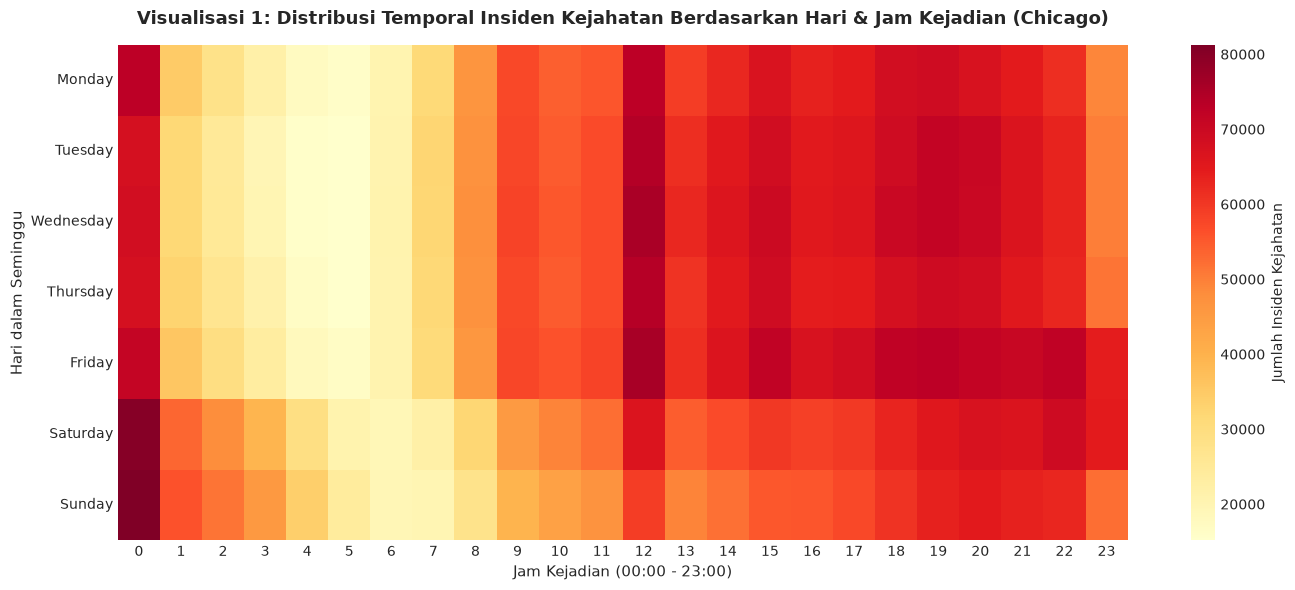

In [55]:
# ==============================================================================
# VISUALISASI 1: Heatmap 2D Jam Kejadian vs Hari dalam Seminggu
# ==============================================================================
pdf_hourly_day = (
    df_enriched
    .groupBy("day_of_week", "hour_of_day")
    .count()
    .toPandas()
)

days_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
heatmap_matrix = pdf_hourly_day.pivot(index="day_of_week", columns="hour_of_day", values="count").reindex(days_order)

plt.figure(figsize=(14, 6))
sns.heatmap(heatmap_matrix, cmap="YlOrRd", fmt=",d", annot=False, cbar_kws={'label': 'Jumlah Insiden Kejahatan'})
plt.title("Visualisasi 1: Distribusi Temporal Insiden Kejahatan Berdasarkan Hari & Jam Kejadian (Chicago)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Jam Kejadian (00:00 - 23:00)", fontsize=11)
plt.ylabel("Hari dalam Seminggu", fontsize=11)
plt.tight_layout()
plt.show()

**Interpretasi Visualisasi 1 (Dinamika Temporal & Ritme Kriminalitas):**
* **Puncak Tengah Malam & Malam Hari:** Aktivitas kriminalitas menunjukkan konsentrasi tertinggi pada rentang malam hingga tengah malam (pukul 20:00 – 00:00), terutama menjelang akhir pekan.
* **Aktivitas Siang Hari yang Padat:** Pada siang hari (pukul 12:00 – 16:00), volume insiden juga tercatat relatif tinggi. Pola ini mengindikasikan dominasi kejahatan opportunistik non-fatal (seperti pencurian properti/toko dan penipuan) yang terjadi seiring mobilitas masyarakat di ruang publik dan area komersial (akan diverifikasi lebih lanjut pada analisis tipologi kejahatan).
* **Perbedaan Siklus Hari Kerja (*Weekday*) vs Akhir Pekan (*Weekend*):** Tingkat kejahatan pada dini hari (pukul 01:00 – 05:00) jauh lebih sedikit di hari kerja dibandingkan akhir pekan. Hal ini berkorelasi kuat dengan siklus jam kerja, mobilitas, dan kesibukan aktivitas masyarakat.
* **Kewaspadaan Pagi Hari:** Periode pagi hari (pukul 05:00 – 08:00) secara konsisten mencatat volume insiden terendah, bertepatan dengan mulainya aktivitas harian saat lingkungan cenderung terpantau aktif dan masyarakat berada dalam kondisi awas (*high vigilance*).


#### Visualisasi 2: Tren Historis Tahunan Volume Kriminalitas & Arrest Rate (Dual-Axis)

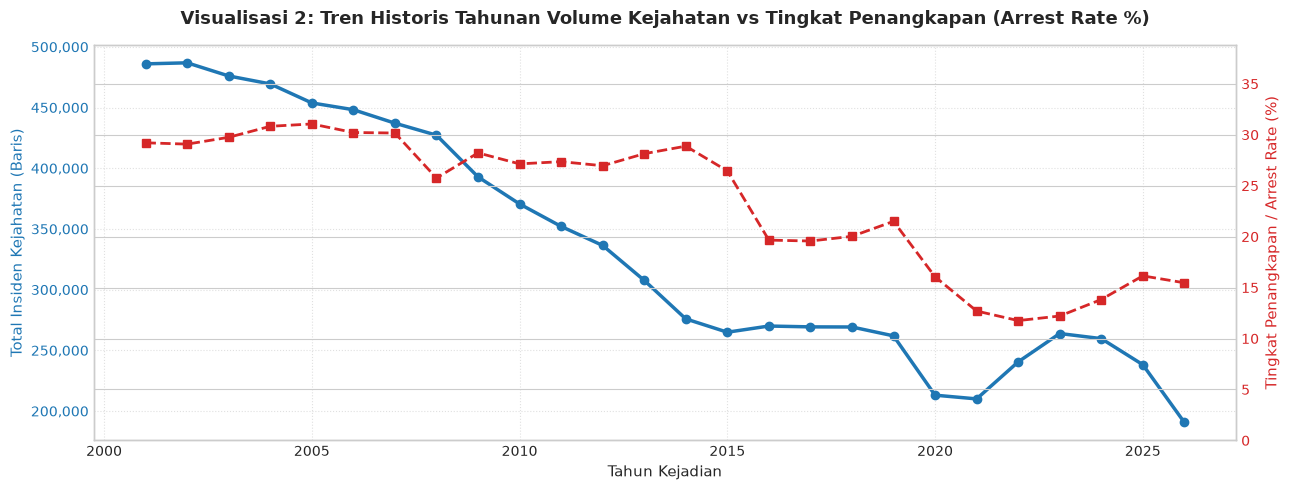

In [56]:
# ==============================================================================
# VISUALISASI 2: Tren Historis Tahunan Volume Kriminalitas & Arrest Rate (Dual-Axis)
# ==============================================================================
pdf_yearly = (
    df_enriched
    .groupBy("year")
    .agg(
        F.count("crime_id").alias("total_incidents"),
        F.round((F.sum(F.when(F.col("is_arrest") == True, 1).otherwise(0)) / F.count("crime_id")) * 100, 2).alias("arrest_rate_pct")
    )
    .orderBy("year")
    .toPandas()
)

fig, ax1 = plt.subplots(figsize=(13, 5))

color1 = '#1f77b4'
ax1.set_xlabel('Tahun Kejadian', fontsize=11)
ax1.set_ylabel('Total Insiden Kejahatan (Baris)', color=color1, fontsize=11)
ax1.plot(pdf_yearly['year'], pdf_yearly['total_incidents'], color=color1, marker='o', linewidth=2.5, label='Total Insiden')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

ax2 = ax1.twinx()
color2 = '#d62728'
ax2.set_ylabel('Tingkat Penangkapan / Arrest Rate (%)', color=color2, fontsize=11)
ax2.plot(pdf_yearly['year'], pdf_yearly['arrest_rate_pct'], color=color2, marker='s', linestyle='--', linewidth=2, label='Arrest Rate (%)')
ax2.tick_params(axis='y', labelcolor=color2)
ax2.set_ylim(0, max(pdf_yearly['arrest_rate_pct']) * 1.25)

plt.title("Visualisasi 2: Tren Historis Tahunan Volume Kejahatan vs Tingkat Penangkapan (Arrest Rate %)", fontsize=13, fontweight='bold', pad=15)
ax1.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

**Interpretasi Visualisasi 2 (Tren Historis & Dekonstruksi Metrik *Arrest Rate*):**
* **Tren Penurunan Volume Kriminalitas:** Sejak tahun 2001 hingga saat ini, total volume insiden kriminalitas di Chicago menunjukkan tren deselerasi jangka panjang yang konsisten (turun dari ~485.000 menjadi ~260.000–290.000 insiden per tahun), yang mengindikasikan perbaikan sistem penegakan hukum dan efektivitas tata kelola kota.
* **Membedah Anomali *Arrest Rate* (Mengapa Menurun dari ~29% ke ~11%?):**
  * *Definisi Metrik:* Di dataset CPD, kolom `arrest` bernilai `True` hanya jika petugas berhasil **langsung menangkap pelaku saat/terkait pelaporan kejadian**. *Arrest Rate* dihitung dari persentase kejadian berujung penangkapan langsung terhadap total insiden.
  * *Bukan Penurunan Kinerja:* Penurunan angka penangkapan dari 29% (2001) ke 11%–12% (saat ini) **bukan** berarti polisi tidak bekerja, melainkan dipicu oleh 3 faktor struktural:
    1. **De-eskalasi Penangkapan Narkotika (*War on Drugs*):** Pada era 2001–2005, operasi tangkap tangan narkotika jalanan sangat masif (>50.000 kasus/tahun dengan *arrest rate* ~99%). Narkotika menyumbang >10% total kejahatan kota dan mendongkrak rata-rata *arrest rate*. Seiring depenalisasi dan legalisasi ganja, penangkapan narkotika anjlok >89% (hanya ~5.400 kasus di 2023), yang secara drastis menurunkan rata-rata penangkapan kota.
    2. **Perubahan Doktrin Patroli (*Consent Decree* & Reformasi Stop-and-Frisk 2015):** Kepolisian Chicago membatasi prosedur penggeledahan massal tanpa alasan kuat di jalan (*investigatory stops*), beralih dari penangkapan preemptif ke respons pelaporan warga (*reactive policing*).
    3. **Pergeseran ke Kejahatan Properti & Siber:** Komposisi kejahatan modern semakin didominasi pencurian properti dan penipuan digital yang pelakunya sudah kabur saat laporan dibuat, sehingga secara alamiah memiliki *arrest rate* rendah (<10%).


#### Visualisasi 3: Komparasi Shift Patroli (Total Insiden vs Arrest Rate %)

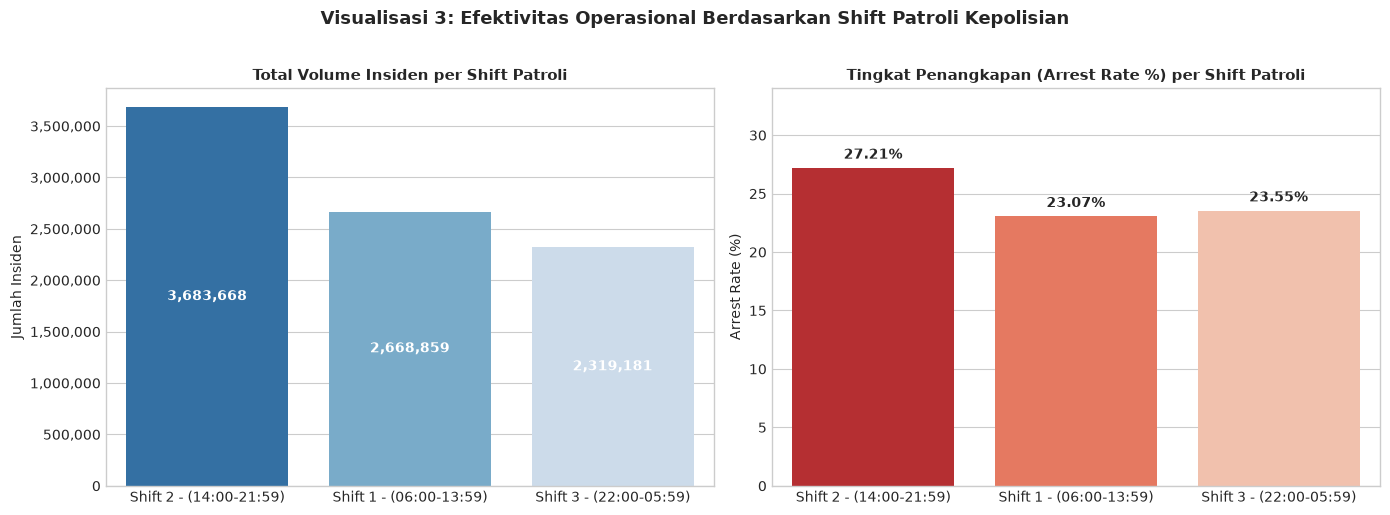

In [57]:
# ==============================================================================
# VISUALISASI 3: Komparasi Shift Patroli (Total Insiden vs Arrest Rate %)
# ==============================================================================
pdf_shifts = (
    df_enriched
    .groupBy("patrol_shift")
    .agg(
        F.count("crime_id").alias("total_incidents"),
        F.round((F.sum(F.when(F.col("is_arrest") == True, 1).otherwise(0)) / F.count("crime_id")) * 100, 2).alias("arrest_rate_pct")
    )
    .orderBy(F.col("total_incidents").desc())
    .toPandas()
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=pdf_shifts, x="patrol_shift", y="total_incidents", hue="patrol_shift", palette="Blues_r", legend=False, ax=ax1)
ax1.set_title("Total Volume Insiden per Shift Patroli", fontsize=11, fontweight='bold')
ax1.set_xlabel("")
ax1.set_ylabel("Jumlah Insiden")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
for p in ax1.patches:
    ax1.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                 ha='center', va='center', color='white', fontweight='bold', fontsize=10)

sns.barplot(data=pdf_shifts, x="patrol_shift", y="arrest_rate_pct", hue="patrol_shift", palette="Reds_r", legend=False, ax=ax2)
ax2.set_title("Tingkat Penangkapan (Arrest Rate %) per Shift Patroli", fontsize=11, fontweight='bold')
ax2.set_xlabel("")
ax2.set_ylabel("Arrest Rate (%)")
ax2.set_ylim(0, max(pdf_shifts['arrest_rate_pct']) * 1.25)
for p in ax2.patches:
    ax2.annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 0.5),
                 ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.suptitle("Visualisasi 3: Efektivitas Operasional Berdasarkan Shift Patroli Kepolisian", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**Interpretasi Visualisasi 3 (Efektivitas Alokasi Shift Patroli Kepolisian):**
* **Dasar Pembagian Tiga Shift:** Pembagian shift mengacu pada regulasi operasional resmi Chicago Police Department (CPD) sebagaimana terdokumentasi pada portal [City of Chicago OIG - Sworn CPD Member Overview](https://igchicago.org/information-portal/data-dashboards/sworn-cpd-member-overview-2/):
  * **Shift 1 (Day Shift):** 06:00 – 13:59
  * **Shift 2 (Evening Shift):** 14:00 – 21:59
  * **Shift 3 (Night/Graveyard Shift):** 22:00 – 05:59
* **Puncak Beban Kejadian di Shift 2:** Volume insiden tertinggi terjadi pada Shift 2 (sore hingga malam). Pola ini selaras dengan Visualisasi 1, karena pada rentang waktu inilah jam pulang kerja, aktivitas komersial, dan interaksi sosial warga mencapai puncaknya.
* **Keseimbangan Volume Shift 3 vs Shift 1:** Total volume pada Shift 3 relatif berimbang dengan Shift 1. Meskipun kejahatan sangat marak pada tengah malam (fase awal Shift 3), angka tersebut mereda secara signifikan memasuki dini hari hingga pagi (02:00 – 06:00), sehingga total akumulasinya sebanding dengan Shift 1.
* **Konteks *Arrest Rate* Antar Shift:** Variasi *arrest rate* antar shift dipengaruhi oleh karakteristik kejahatan: kejahatan di shift sore/malam lebih sering melibatkan interaksi fisik langsung di ruang publik (peluang penangkapan lebih tinggi), sedangkan shift pagi/siang banyak mencatat laporan pencurian properti atau kendaraan pasca-kejadian.


### 4.2 Visualisasi Tipologi Kriminalitas & Efektivitas Penegakan Hukum

#### Visualisasi 4: Top 15 Kategori Kejahatan (Primary Type) Terbanyak

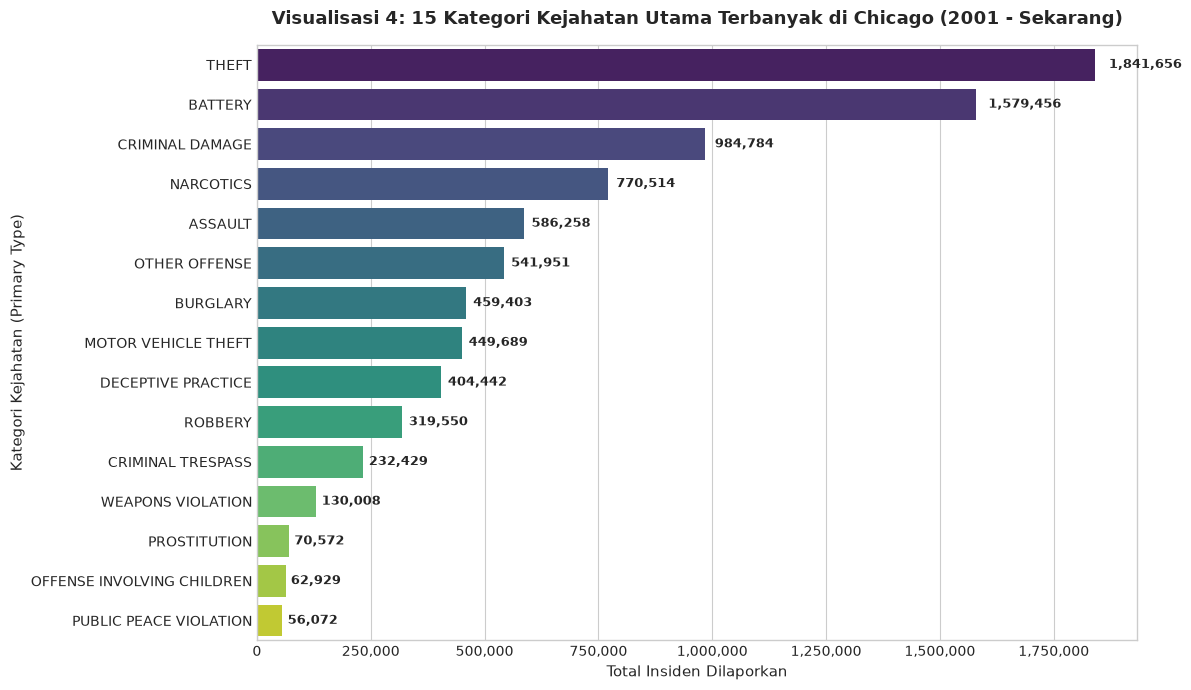

In [58]:
# ==============================================================================
# VISUALISASI 4: Top 15 Kategori Kejahatan (Primary Type) Terbanyak
# ==============================================================================
pdf_top_crimes = (
    df_enriched
    .groupBy("primary_type")
    .agg(F.count("crime_id").alias("total_incidents"))
    .orderBy(F.col("total_incidents").desc())
    .limit(15)
    .toPandas()
)

plt.figure(figsize=(12, 7))
sns.barplot(data=pdf_top_crimes, y="primary_type", x="total_incidents", hue="primary_type", palette="viridis", legend=False)
plt.title("Visualisasi 4: 15 Kategori Kejahatan Utama Terbanyak di Chicago (2001 - Sekarang)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Total Insiden Dilaporkan", fontsize=11)
plt.ylabel("Kategori Kejahatan (Primary Type)", fontsize=11)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
for i, v in enumerate(pdf_top_crimes['total_incidents']):
    plt.text(v + (v * 0.01), i, f" {v:,}", va='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretasi Visualisasi 4 (Tipologi Kejahatan Dominan):**
* **Dominasi Kejahatan Properti & Kontak Fisik:** Dari seluruh kategori kejahatan di Chicago, *Theft* (pencurian tanpa kekerasan) dan *Battery* (kontak fisik ofensif/pemukulan) menempati peringkat teratas dengan volume kumulatif yang jauh melampaui kategori lainnya (masing-masing melampaui 1,5 juta insiden).
* **Indikasi Faktor Ekonomi & Gesekan Sosial:** Tingginya volume pencurian (*Theft*, *Burglary*, *Motor Vehicle Theft*) mengindikasikan kuatnya pengaruh motif ekonomi dan ketimpangan finansial, di mana barang berharga menjadi sasaran empuk kejahatan oportunistik. Di sisi lain, tingginya angka *Battery* dan *Assault* mencerminkan tingginya potensi gesekan antarpribadi di ruang publik maupun privat.
* **Tingkat Keparahan Relatif:** Sebagian besar insiden yang mendominasi volume kota tergolong kejahatan properti atau pelanggaran ketertiban umum, sedangkan kejahatan kekerasan ekstrem seperti pembunuhan (*Homicide*) secara statistik memiliki frekuensi yang relatif sangat kecil dalam keseluruhan volume agregat.


#### Visualisasi 5: Sebaran Volume Insiden vs Tingkat Penangkapan (Arrest Rate %) per Jenis Kejahatan

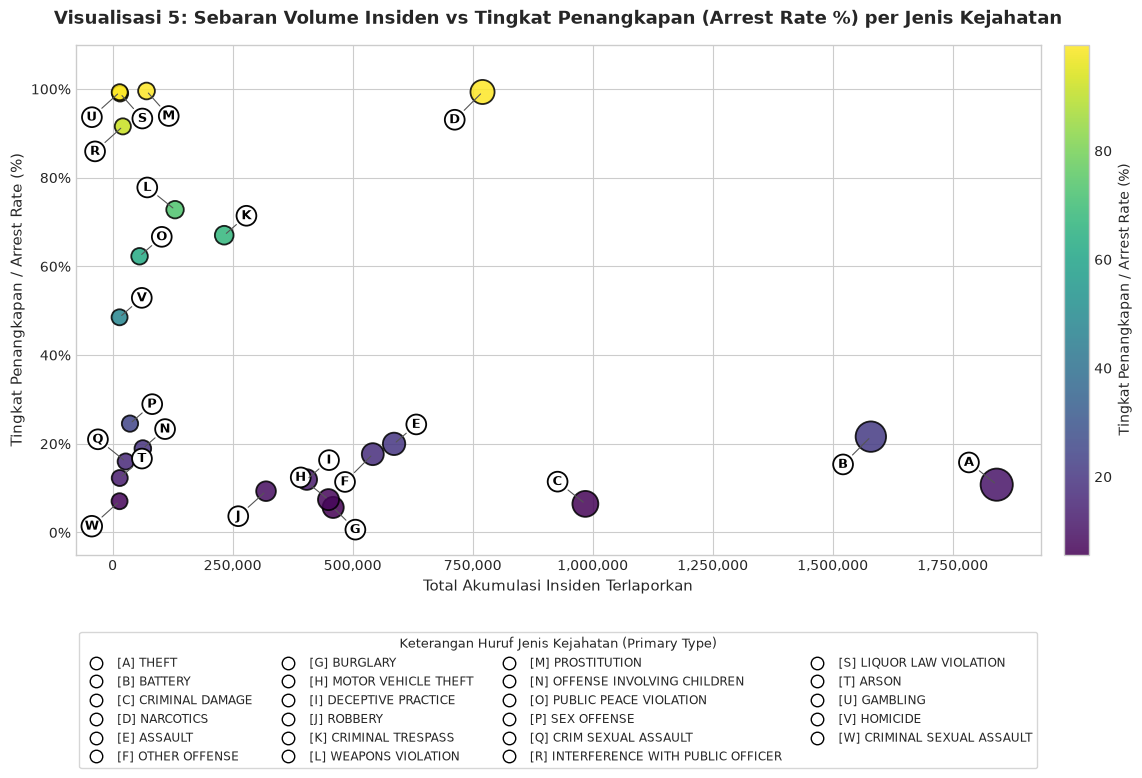

In [59]:
# ==============================================================================
# VISUALISASI 5: Scatter Plot Volume Insiden vs Tingkat Penangkapan (Bebas Tumpukan)
# ==============================================================================
pdf_crime_rates = (
    df_crime_summary
    .filter(F.col("total_incidents") >= 10000)
    .orderBy(F.col("total_incidents").desc())
    .toPandas()
)

# Label huruf berurutan berdasarkan volume insiden
pdf_crime_rates['label'] = [chr(65 + i) for i in range(len(pdf_crime_rates))]

# Pemetaan posisi offset bebas-tabrakan (Collision-Free Offsets)
# Setiap titik memiliki ruang eksklusif dengan garis penunjuk halus
offsets_map = {
    'A': (-20, 16),   # THEFT: kiri atas
    'B': (-20, -20),  # BATTERY: kiri bawah
    'C': (-20, 16),   # CRIMINAL DAMAGE: kiri atas
    'D': (-20, -20),  # NARCOTICS: kiri bawah
    'E': (16, 14),    # ASSAULT: kanan atas
    'F': (-20, -20),  # OTHER OFFENSE: kiri bawah
    'G': (16, -16),   # BURGLARY: kanan bawah
    'H': (-20, 16),   # MOTOR VEHICLE THEFT: kiri atas
    'I': (16, 14),    # DECEPTIVE PRACTICE: kanan atas
    'J': (-20, -18),  # ROBBERY: kiri bawah
    'K': (16, 14),    # CRIMINAL TRESPASS: kanan atas
    'L': (-20, 16),   # WEAPONS VIOLATION: kiri atas
    'M': (16, -18),   # PROSTITUTION: kanan bawah
    'N': (16, 14),    # OFFENSE INVOLVING CHILDREN: kanan atas
    'O': (16, 14),    # PUBLIC PEACE VIOLATION: kanan atas
    'P': (16, 14),    # SEX OFFENSE: kanan atas
    'Q': (-20, 16),   # CRIM SEXUAL ASSAULT: kiri atas
    'R': (-20, -18),  # INTERFERENCE: kiri bawah
    'S': (16, -18),   # LIQUOR LAW: kanan bawah
    'T': (16, 14),    # ARSON: kanan atas
    'U': (-20, -18),  # GAMBLING: kiri bawah
    'V': (16, 14),    # HOMICIDE: kanan atas
    'W': (-20, -18)   # CRIMINAL SEXUAL ASSAULT: kiri bawah
}

fig, ax = plt.subplots(figsize=(15, 8.5))

scatter = ax.scatter(
    pdf_crime_rates['total_incidents'],
    pdf_crime_rates['arrest_rate_pct'],
    s=pdf_crime_rates['total_incidents'] / 4500 + 130,
    c=pdf_crime_rates['arrest_rate_pct'],
    cmap='viridis',
    edgecolors='black',
    linewidth=1.3,
    alpha=0.85,
    zorder=3
)

cbar = plt.colorbar(scatter, ax=ax, pad=0.02)
cbar.set_label('Tingkat Penangkapan / Arrest Rate (%)', fontsize=10)

# Penempatan huruf dengan kontras tinggi (lingkaran putih solid + border hitam tajam)
for _, r in pdf_crime_rates.iterrows():
    x = r['total_incidents']
    y = r['arrest_rate_pct']
    letter = r['label']
    off = offsets_map.get(letter, (10, 10))
    
    ax.annotate(
        letter,
        xy=(x, y),
        xytext=off,
        textcoords='offset points',
        fontsize=9.5,
        fontweight='bold',
        color='black',
        ha='center',
        va='center',
        bbox=dict(boxstyle='circle,pad=0.25', facecolor='#ffffff', edgecolor='#000000', lw=1.3, alpha=0.98),
        arrowprops=dict(arrowstyle='-', color='#555555', lw=0.8),
        zorder=6
    )

ax.set_title("Visualisasi 5: Sebaran Volume Insiden vs Tingkat Penangkapan (Arrest Rate %) per Jenis Kejahatan", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Total Akumulasi Insiden Terlaporkan", fontsize=11)
ax.set_ylabel("Tingkat Penangkapan / Arrest Rate (%)", fontsize=11)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda val, loc: f"{val:.0f}%"))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda val, loc: f"{int(val):,}"))
ax.set_ylim(-5, 110)

# Legenda 4 kolom terstruktur di bawah grafik
legend_labels = [f"[{r['label']}] {r['primary_type']}" for _, r in pdf_crime_rates.iterrows()]
handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='#ffffff', markeredgecolor='#000000', markersize=9, label=lbl) for lbl in legend_labels]

ax.legend(
    handles=handles,
    loc='upper center',
    bbox_to_anchor=(0.5, -0.14),
    ncol=4,
    fontsize=8.5,
    frameon=True,
    title="Keterangan Huruf Jenis Kejahatan (Primary Type)",
    title_fontsize=9.5
)

plt.subplots_adjust(bottom=0.28)
plt.show()

**Interpretasi Visualisasi 5 (Sebaran Volume vs *Arrest Rate* & Validasi Metrik Narkotika):**
* **Verifikasi Metrik *Arrest Rate* pada Kasus Narkotika & Pelanggaran Khusus:** 
  * Terdapat fenomena kontras di mana kejahatan seperti *Narcotics* [D], *Prostitution* [M], dan *Gambling* [U] memiliki tingkat penangkapan (*arrest rate*) yang mendekati **100%**, meskipun mayoritas kejahatan lainnya berada jauh di bawah 25%.
  * *Bukan Kesalahan Komputasi/Generasi Data:* Hal ini mencerminkan perbedaan mendasar antara **Kejahatan Proaktif (*Proactive Enforcement*)** vs **Kejahatan Reaktif (*Victim-Reported Crime*)**:
    1. **Kejahatan Proaktif (Narkotika/Prostitusi/Senjata):** Kejahatan ini hampir tidak pernah dilaporkan oleh korban melalui panggilan darurat (911). Pencatatan laporan ke sistem polisi hampir selalu terjadi *hanya ketika* polisi melakukan razia, operasi tangkap tangan, atau penangkapan langsung di tempat. Oleh karena itu, adanya pencatatan insiden hampir selalu bertepatan dengan adanya penangkapan (`arrest = True`).
    2. **Kejahatan Reaktif (Pencurian/Pembobolan):** Sebaliknya, kasus seperti *Theft* [A], *Burglary* [G], dan *Motor Vehicle Theft* [H] dilaporkan oleh korban setelah peristiwa terjadi dan pelakunya telah melarikan diri, sehingga *arrest rate*-nya secara natural berada di bawah 11%.
* **Polarisasi Penegakan Hukum:** Visualisasi ini membuktikan bahwa efektivitas penangkapan langsung polisi sangat tinggi pada pelanggaran regulasi yang ditindak secara proaktif di lapangan, namun menghadapi tantangan pembuktian yang berat pada kejahatan properti massal.


#### Visualisasi 6: Top 10 Lokasi Fisik Kejadian Kejahatan & Proporsi Domestik

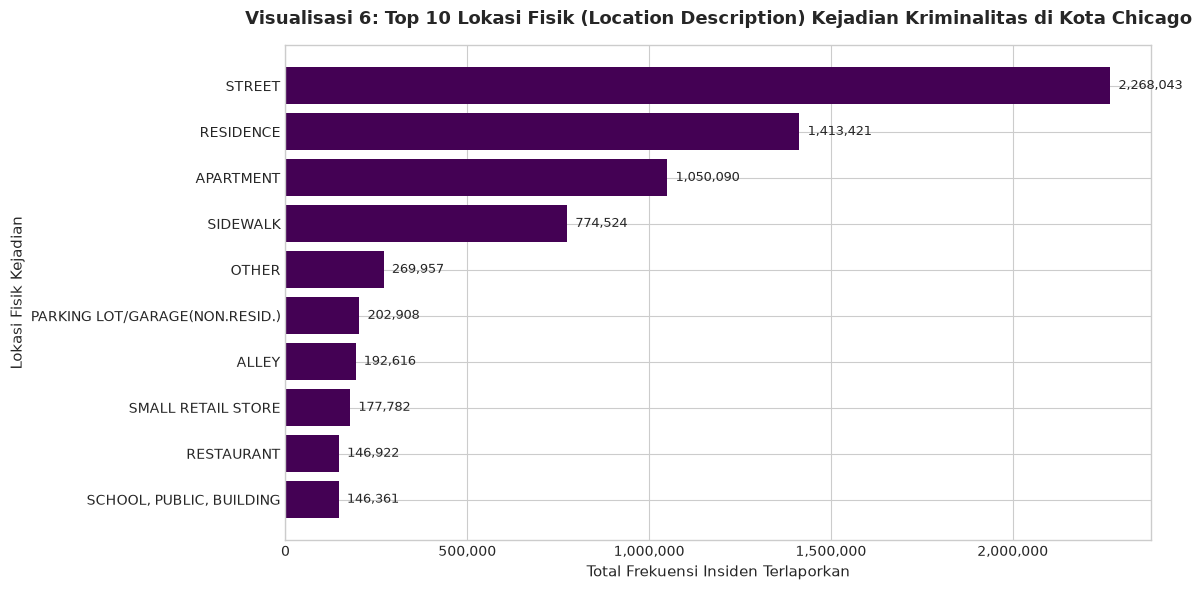

In [60]:
# ==============================================================================
# VISUALISASI 6: Top 10 Lokasi Fisik Kejadian Kejahatan & Proporsi Domestik
# ==============================================================================
pdf_locations = (
    df_enriched
    .filter(F.col("location_description").isNotNull())
    .groupBy("location_description")
    .agg(
        F.count("crime_id").alias("total_incidents"),
        F.round((F.sum(F.when(F.col("is_domestic") == True, 1).otherwise(0)) / F.count("crime_id")) * 100, 2).alias("domestic_pct")
    )
    .orderBy(F.col("total_incidents").desc())
    .limit(10)
    .toPandas()
)

plt.figure(figsize=(12, 6))
bars = plt.barh(pdf_locations['location_description'][::-1], pdf_locations['total_incidents'][::-1], color='#440154')
plt.title("Visualisasi 6: Top 10 Lokasi Fisik (Location Description) Kejadian Kriminalitas di Kota Chicago", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Total Frekuensi Insiden Terlaporkan", fontsize=11)
plt.ylabel("Lokasi Fisik Kejadian", fontsize=11)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

for bar in bars:
    w = bar.get_width()
    plt.text(w + (max(pdf_locations['total_incidents']) * 0.01), bar.get_y() + bar.get_height()/2,
             f"{int(w):,}", ha='left', va='center', fontsize=9)

plt.tight_layout()
plt.show()

**Interpretasi Visualisasi 6 (Konsentrasi Lokasi Fisik Kejadian):**
* **Dominasi Ruang Publik Terbuka (Jalanan):** Lokasi dengan frekuensi kejahatan tertinggi di Chicago secara mutlak terkonsentrasi di jalanan umum (*Street*), disusul oleh area trotoar (*Sidewalk*). Jika digabungkan, ruang publik jalanan menyerap porsi terbesar dari total kriminalitas kota.
* **Korelasi dengan Dinamika Aktivitas & Waktu Kejadian:**
  * Konsentrasi kejahatan jalanan ini berhubungan erat dengan pola temporal pada Visualisasi 1:
    * Pada siang hingga sore hari, jalanan menjadi pusat mobilitas massa dan kerumunan yang memicu kejahatan oportunistik seperti pencurian barang dan penipuan.
    * Pada malam hingga dini hari, jalanan yang cenderung lengang, minim pengawasan alami (*natural surveillance*), dan minim penerangan menjadi lokasi rentan bagi aksi kekerasan fisik, perampokan, dan pelanggaran hukum jalanan lainnya.
* **Kerawanan Area Domestik:** Lokasi terbanyak kedua berada pada lingkungan privat (*Residence* dan *Apartment*), yang menyumbang proporsi signifikan dari insiden perselisihan domestik (*domestic disputes*).


### 4.3 Visualisasi Disparitas Sosio-Ekonomi Wilayah Komunitas

#### Visualisasi 7: Korelasi Hardship Index vs Volume Kejahatan (Highlight Kawasan Ekstrim)

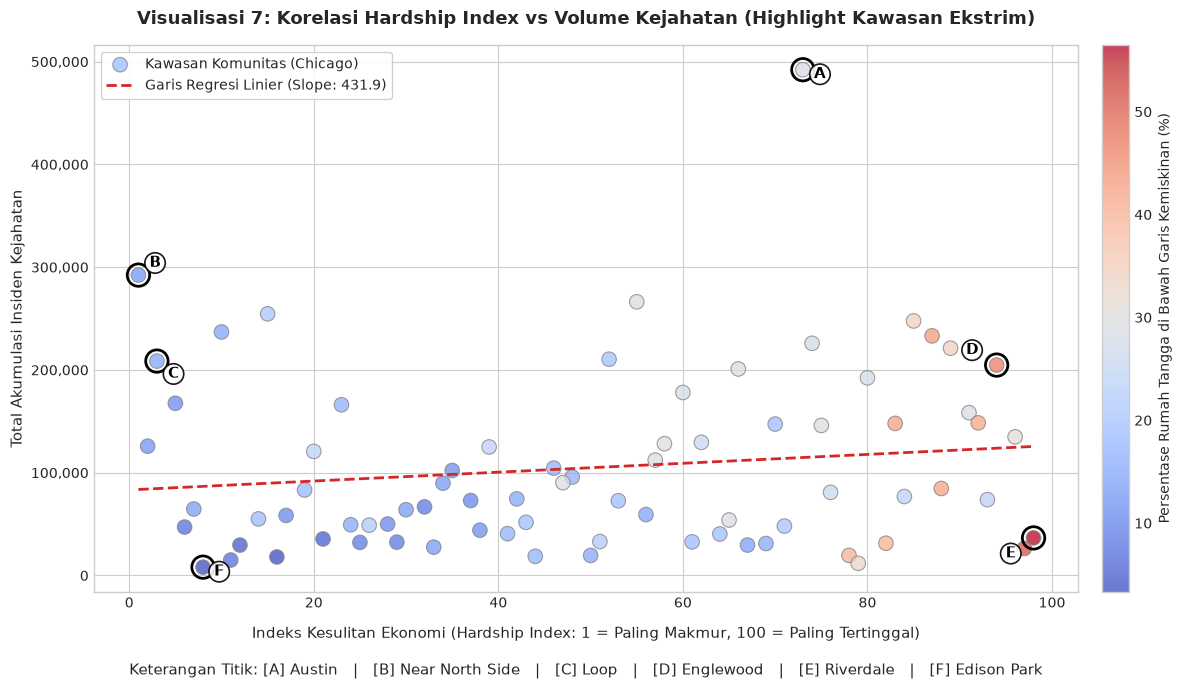

In [61]:
# ==============================================================================
# VISUALISASI 7: Scatter Plot Hardship Index vs Volume Kejahatan (Highlight Kawasan Ekstrim)
# ==============================================================================
pdf_socio_scatter = (
    df_socio_crime
    .join(df_census.select("community_area_id", "pct_below_poverty"), on="community_area_id", how="left")
    .toPandas()
)

# ------------------------------------------------------------------------------
# 1. PERHITUNGAN MATEMATIS OUTLIER & REGRESI LINIER (STATISTICAL CRITERIA)
# ------------------------------------------------------------------------------
x_vals_all = pdf_socio_scatter['hardship_index'].values
y_vals_all = pdf_socio_scatter['total_crimes'].values
slope, intercept = np.polyfit(x_vals_all, y_vals_all, 1)
y_pred_all = slope * x_vals_all + intercept

# Residuals & Z-score (digunakan untuk pertanggungjawaban statistik deteksi outlier)
residuals = y_vals_all - y_pred_all
std_res = np.std(residuals)
pdf_socio_scatter['z_residual'] = residuals / std_res

# Titik ekstrim yang di-highlight berbasis kriteria statistik:
# [A] Austin: Max Kasus (Y_max) & Residual Outlier (z = +4.46)
# [B] Near North Side: Min Hardship (X_min) & Residual Outlier (z = +2.47)
# [C] Loop: Pusat Bisnis / Outlier Anomali (z = +1.77)
# [D] Englewood: Klaster Rentan Tinggi (Hardship > 90 & Kasus > 200k)
# [E] Riverdale: Max Hardship (X_max = 98.0, Kemiskinan 56.5%)
# [F] Edison Park: Min Kasus (Y_min = 8.068 Kasus)
math_highlights = [
    {'id': 'A', 'area': 'Austin', 'offset': (8, -6)},
    {'id': 'B', 'area': 'Near North Side', 'offset': (8, 6)},
    {'id': 'C', 'area': 'Loop', 'offset': (8, -12)},
    {'id': 'D', 'area': 'Englewood', 'offset': (-22, 8)},
    {'id': 'E', 'area': 'Riverdale', 'offset': (-20, -14)},
    {'id': 'F', 'area': 'Edison Park', 'offset': (8, -6)}
]

# ------------------------------------------------------------------------------
# 2. PLOTTING SCATTER PLOT
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(13, 7))

scatter = ax.scatter(
    pdf_socio_scatter['hardship_index'],
    pdf_socio_scatter['total_crimes'],
    c=pdf_socio_scatter['pct_below_poverty'],
    cmap='coolwarm',
    s=110,
    edgecolors='gray',
    linewidth=0.8,
    alpha=0.75,
    label='Kawasan Komunitas (Chicago)'
)

cbar = plt.colorbar(scatter, ax=ax, pad=0.02)
cbar.set_label('Persentase Rumah Tangga di Bawah Garis Kemiskinan (%)', fontsize=10)

# Garis Regresi Linier
x_line = np.linspace(pdf_socio_scatter['hardship_index'].min(), pdf_socio_scatter['hardship_index'].max(), 100)
ax.plot(x_line, slope * x_line + intercept, color='#d62728', linestyle='--', linewidth=2, label=f'Garis Regresi Linier (Slope: {slope:.1f})')

# Menandai titik ekstrim hanya dengan lingkaran dan huruf sederhana
keterangan_list = []
for item in math_highlights:
    row = pdf_socio_scatter[pdf_socio_scatter['community_area_name'].str.lower() == item['area'].lower()]
    if not row.empty:
        r = row.iloc[0]
        x_pt, y_pt = r['hardship_index'], r['total_crimes']
        
        # Cincin penanda ganda pada titik
        ax.scatter(x_pt, y_pt, s=260, facecolors='none', edgecolors='black', linewidth=2.0, zorder=5)
        
        # Huruf penanda di samping titik
        ax.annotate(
            item['id'],
            xy=(x_pt, y_pt),
            xytext=item['offset'],
            textcoords='offset points',
            fontsize=10.5,
            fontweight='bold',
            color='black',
            bbox=dict(boxstyle='circle,pad=0.2', facecolor='white', edgecolor='black', alpha=0.9, lw=1.2),
            zorder=6
        )
        keterangan_list.append(f"[{item['id']}] {r['community_area_name']}")

# Keterangan sederhana di bawah grafik (tanpa tabel besar)
keterangan_teks = "Keterangan Titik: " + "   |   ".join(keterangan_list)

ax.set_title("Visualisasi 7: Korelasi Hardship Index vs Volume Kejahatan (Highlight Kawasan Ekstrim)", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel(f"Indeks Kesulitan Ekonomi (Hardship Index: 1 = Paling Makmur, 100 = Paling Tertinggal)\n\n{keterangan_teks}", fontsize=11, labelpad=10)
ax.set_ylabel("Total Akumulasi Insiden Kejahatan", fontsize=11)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda val, loc: "{:,}".format(int(val))))
ax.legend(loc='upper left', frameon=True, framealpha=0.9)

plt.tight_layout()
plt.show()

**Interpretasi Visualisasi 7 (Korelasi *Hardship Index* vs Volume & Paradoks Populasi):**
* **Sebaran Anomali Ekstrim:** Visualisasi menunjukkan adanya anomali yang mencolok terhadap ekspektasi linier:
  * **Wilayah *High Hardship* dengan Volume Kasus Rendah (Contoh: Riverdale [D]):** Memiliki indeks kesulitan ekonomi tertinggi di Chicago (98.0) dan tingkat kemiskinan ekstrem (>56%), namun mencatatkan total akumulasi kejahatan yang relatif rendah (~36.500 kasus).
  * **Wilayah *Low Hardship* dengan Volume Kasus Sangat Tinggi (Contoh: Near North Side [B] & Loop [C]):** Memiliki tingkat kemakmuran tinggi, namun mencatat angka kriminalitas kumulatif ratusan ribu kasus.
* **Hipotesis Bias Ukuran Populasi (*Population-Size Bias*):**
  * Paradoks ini kuat diduga dipicu oleh ketimpangan jumlah populasi penduduk di masing-masing wilayah komunitas (*community area*). Wilayah seperti Riverdale memiliki populasi penduduk yang sangat kecil (~7.200 jiwa), sementara Austin [A] berpenduduk ~100.000 jiwa.
  * Meskipun volume kasus absolut di wilayah tertinggal tampak rendah, **angka kriminalitas per kapita (*crime rate per 1,000 residents*)** di wilayah tersebut sebenarnya bisa jadi sangat tinggi. Hal ini membuktikan perlunya normalisasi berbasis data populasi sensus pada analisis lanjutan (Bab 6).


#### Visualisasi 8: Komparasi Rata-rata Beban Kriminalitas & Pendapatan per Kapita per Tier Wilayah

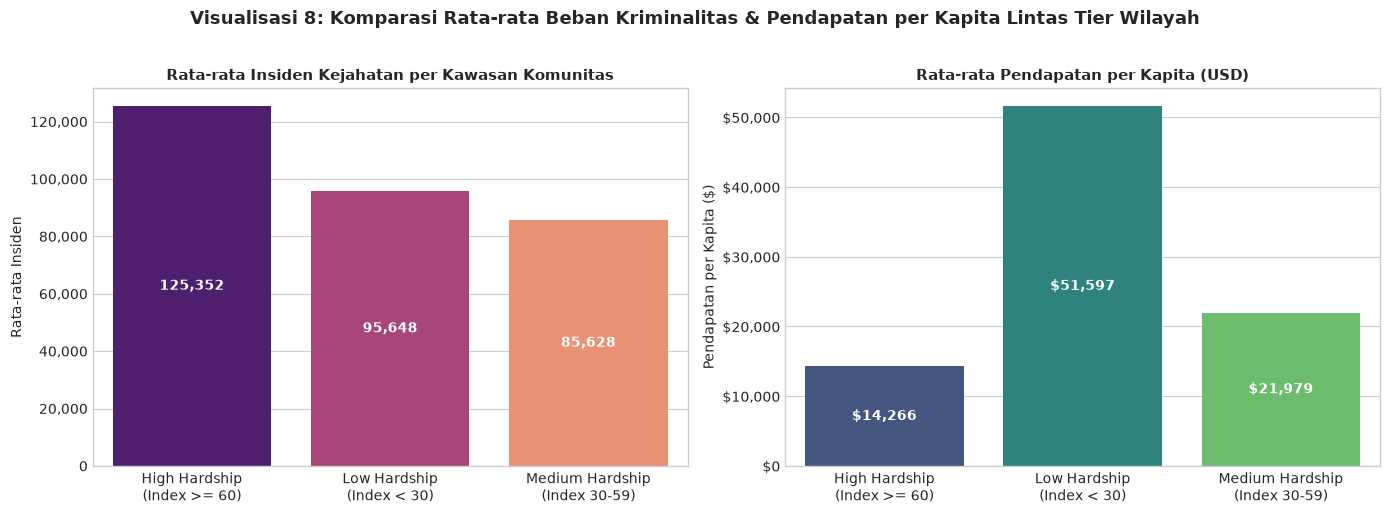

In [62]:
# ==============================================================================
# VISUALISASI 8: Komparasi Rata-rata Beban Kriminalitas & Pendapatan per Kapita per Tier Wilayah
# ==============================================================================
pdf_tiers = spark.sql("""
SELECT
    CASE
        WHEN hardship_index >= 60 THEN 'High Hardship\n(Index >= 60)'
        WHEN hardship_index >= 30 AND hardship_index < 60 THEN 'Medium Hardship\n(Index 30-59)'
        ELSE 'Low Hardship\n(Index < 30)'
    END AS socioeconomic_tier,
    COUNT(DISTINCT community_area_id) AS num_communities,
    ROUND(COUNT(crime_id) * 1.0 / COUNT(DISTINCT community_area_id), 0) AS avg_crimes_per_area,
    ROUND(AVG(per_capita_income), 0) AS avg_income,
    ROUND(SUM(CASE WHEN is_arrest = true THEN 1 ELSE 0 END) * 100.0 / COUNT(crime_id), 2) AS arrest_rate
FROM vw_chicago_crimes_joined
GROUP BY socioeconomic_tier
ORDER BY avg_crimes_per_area DESC
""").toPandas()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Rata-rata Insiden Kejahatan per Area Komunitas
sns.barplot(data=pdf_tiers, x="socioeconomic_tier", y="avg_crimes_per_area", hue="socioeconomic_tier", palette="magma", legend=False, ax=ax1)
ax1.set_title("Rata-rata Insiden Kejahatan per Kawasan Komunitas", fontsize=11, fontweight='bold')
ax1.set_xlabel("")
ax1.set_ylabel("Rata-rata Insiden")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
for p in ax1.patches:
    ax1.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                 ha='center', va='center', color='white', fontweight='bold', fontsize=10)

# Subplot 2: Rata-rata Pendapatan per Kapita (USD)
sns.barplot(data=pdf_tiers, x="socioeconomic_tier", y="avg_income", hue="socioeconomic_tier", palette="viridis", legend=False, ax=ax2)
ax2.set_title("Rata-rata Pendapatan per Kapita (USD)", fontsize=11, fontweight='bold')
ax2.set_xlabel("")
ax2.set_ylabel("Pendapatan per Kapita ($)")
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "${:,.0f}".format(x)))
for p in ax2.patches:
    ax2.annotate(f"${int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                 ha='center', va='center', color='white', fontweight='bold', fontsize=10)

plt.suptitle("Visualisasi 8: Komparasi Rata-rata Beban Kriminalitas & Pendapatan per Kapita Lintas Tier Wilayah", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**Interpretasi Visualisasi 8 (Komparasi Lintas Tier Sosio-Ekonomi & Daya Tarik Ekonomi):**
* **Beban Kriminalitas di Wilayah *High Hardship*:** Kelompok wilayah dengan *High Hardship* (Indeks $\ge 60$) secara konsisten menanggung rata-rata insiden kejahatan tertinggi per komunitas, merefleksikan dampak kerentanan ekonomi, keterbatasan infrastruktur, dan kemiskinan struktural.
* **Dinamika Menarik: *Low Hardship* Melampaui *Medium Hardship*:**
  * Meskipun wilayah *Low Hardship* (Indeks $< 30$) memiliki pendapatan per kapita tertinggi, rata-rata volume kejahatannya justru **lebih tinggi** dibandingkan wilayah *Medium Hardship*.
* **Penjelasan Daya Tarik Aktivitas Ekonomi (*Economic Attractiveness*):**
  * Wilayah berpenghasilan tinggi (*Low Hardship*, seperti kawasan pusat bisnis Loop dan area komersial utama) merupakan pusat aktivitas ekonomi, pariwisata, dan perputaran uang.
  * Konsentrasi kekayaan dan fasilitas publik ini menciptakan sasaran kejahatan (*attractive targets*) yang memikat pelaku kejahatan oportunistik dari luar wilayah untuk datang dan berbuat kriminal di sana (sesuai teori kriminologi *Routine Activity Theory*). Sebaliknya, kawasan *Medium Hardship* yang didominasi permukiman warga stabil memiliki mobilitas pendatang yang lebih rendah.


# BAB 5: PREPROCESSING & PEMERIKSAAN KUALITAS DATA


# BAB 6: ANALISIS LANJUTAN & MACHINE LEARNING


# BAB 7: TEMUAN BERBASIS BUKTI, KETERBATASAN, & REKOMENDASI
